##Carregamento da base

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
dados = pd.read_csv("dados_tratados.csv")

In [3]:
dados.head()

,ID,MACRORREG_OCOR,COD_UF_OCOR,UF_OCOR,COD_MUN_OCOR,MUN_OCOR,DATA_OCOR,SE_OCOR,MES_OCOR,ANO_OCOR,MONITORAMENTO_OCOR
0,1,CO,52,GO,521100,ITAPIRAPUÃ,NaN,NaN,2.0,2000,1999/2000
1,2,CO,52,GO,521970,SANTA TEREZINHA DE GOIÁS,NaN,NaN,NaN,2000,1999/2000
2,3,CO,52,GO,521520,NOVO BRASIL,NaN,NaN,2.0,2000,1999/2000
3,4,SE,31,MG,310450,ARINOS,NaN,NaN,2.0,2000,1999/2000
4,5,SE,31,MG,310820,BONFINÓPOLIS DE MINAS,NaN,NaN,4.0,2000,1999/2000


##Indicadores

In [4]:
total = len(dados)
print("Total de epizootias:", total)

Total de epizootias: 2637


In [5]:
por_ano = (
    dados.groupby("ANO_OCOR")["ID"]
    .count()
    .sort_index()
)

anos = por_ano.sort_values(ascending=False)
print("Ano de pico:")
print(anos.head(1))

Ano de pico:
ANO_OCOR
2017    869
Name: ID, dtype: int64


In [9]:
macro = (
    dados.groupby("MACRORREG_OCOR")["ID"]
    .count()
    .sort_values(ascending=False)
)

print("Macrorregião líder:")
print(macro.head(1))

Macrorregião líder:
MACRORREG_OCOR
SE    1431
Name: ID, dtype: int64


In [7]:
ufs = (
    dados.groupby("UF_OCOR")["ID"]
    .count()
    .sort_values(ascending=False)
)

print("Estado líder:")
print(ufs.head(1))

Estado líder:
UF_OCOR
SP    941
Name: ID, dtype: int64


In [10]:
meses = dados["MES_OCOR"].value_counts().sort_values(ascending=False)
print("Mês mais frequente:")
print(meses.head(1))

Mês mais frequente:
MES_OCOR
1.0    562
Name: count, dtype: int64


##Gráfico 1

####Pergunta: em que ano ocorreu o pico e como os registros mudaram ao longo dos anos?

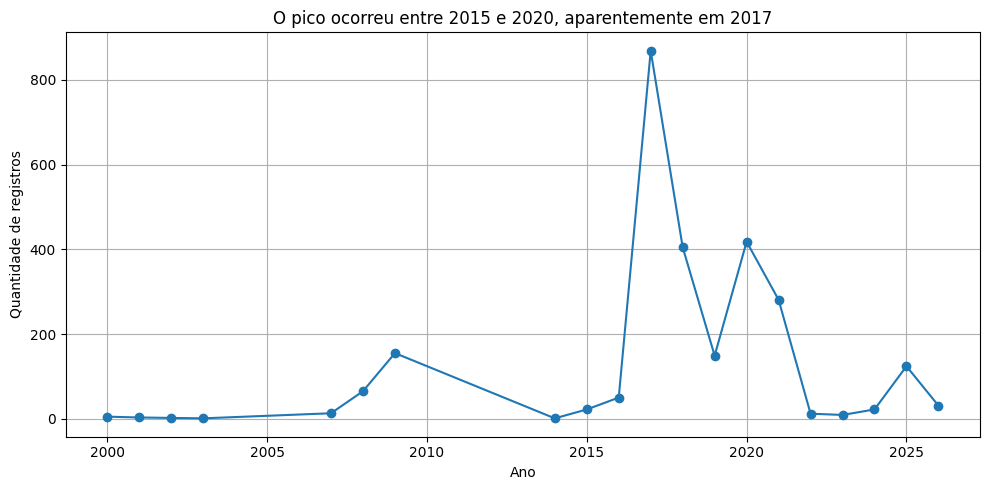

In [13]:
por_ano.plot(
    kind="line",
    marker="o",
    figsize=(10, 5)
)
plt.title("O pico ocorreu entre 2015 e 2020, aparentemente em 2017")
plt.xlabel("Ano")
plt.ylabel("Quantidade de registros")
plt.grid()
plt.tight_layout()
plt.show()

Interpretação: a linha mostra picos seguidos de quedas (2017, 2020 e 2025), e não crescimento contínuo. 2017 fica cerca de 108% acima do segundo maior ano (2020).


##Gráfico 2

####Pergunta que responde: quais macrorregiões concentram mais registros?

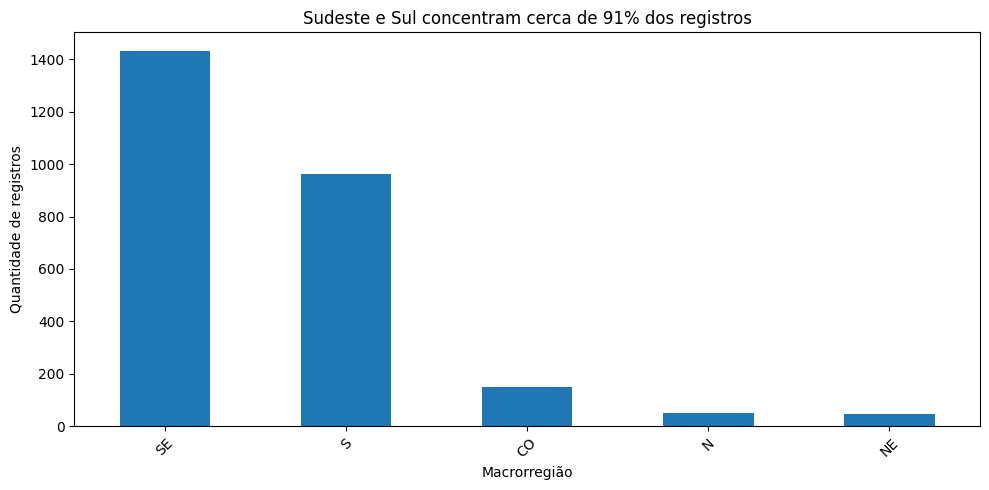

In [15]:
macro.plot(
    kind="bar",
    figsize=(10, 5)
)
plt.title("Sudeste e Sul concentram cerca de 91% dos registros")
plt.xlabel("Macrorregião")
plt.ylabel("Quantidade de registros")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Interpretação: Sergipe (1.431) e São Paulo (961) concentram quase todos os registros, enquanto N (49) e NE (48) têm muito poucos.

##Gráfico 3

####Pergunta que responde: em que época do ano os registros se concentram?

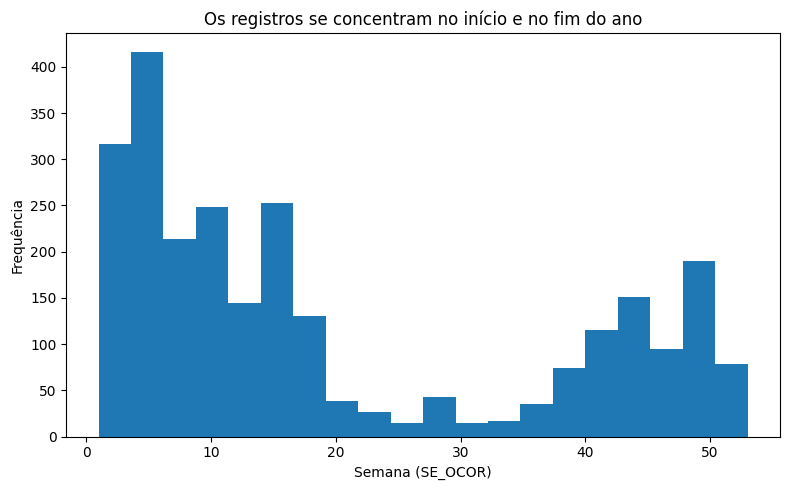

In [16]:
dados["SE_OCOR"].plot(
    kind="hist",
    bins=20,
    figsize=(8, 5)
)
plt.title("Os registros se concentram no início e no fim do ano")
plt.xlabel("Semana (SE_OCOR)")
plt.ylabel("Frequência")
plt.tight_layout()
plt.show()

Interpretação: as barras mais altas ficam nas primeiras semanas do ano (cerca de 1 a 19) e voltam a subir perto do fim (cerca de 38 a 53), com um vale no meio. Isso combina com a análise por mês, em que junho a agosto têm menos de 50 registros cada.